# Syllables vs continuous movement, before stimulus onset

Does the neuromodulator signal track *which* movement syllable the mouse is in, or only *how much* it moves? Notebook 7 (old section 3 and 4c) found that syllables add nothing beyond the continuous movement signals. That comparison had three weaknesses, which this notebook addresses:

1. **Task-evoked activity mixed in.** It used all of −1 to +1 s around stimulus and feedback, where stimulus and reward responses dominate the signal and the movements are themselves locked to the task. Here: **pre-stimulus only**, −1 to 0 s before stimulus onset. The previous feedback is always ≥ ~1.2 s earlier, so the whole second is pre-stimulus on every trial (no masking needed).
2. **Unequal temporal context.** The syllables come from wavelet features computed over a time window around each frame, while the continuous signals were read at a single instant. Here, both can enter with **lags**: every predictor at t − lag, lag = −0.5 … +0.5 s in 100 ms steps. A positive lag means movement before the photometry, which is the expected direction given GCaMP kinetics.
3. **One penalty for everything.** With a single ridge penalty, adding many weak columns (9 syllable indicators × 11 lags = 99) forces a compromise penalty. That also shrinks the useful columns, so R²(both) can drop below R²(movement) as an artefact of the fit. Here: **banded ridge**, with one penalty per block (baseline, movement, syllables), all chosen by cross-validation inside the training set (Nunez-Elizalde et al. 2019).

**Data.** Every fiber-session of the export, with the stimulus-aligned photometry averaged into 100 ms bins (10 per trial). Predictors come from the 30 Hz states file, averaged over the same bins:
- **movement**: log(1 + ·) of left-paw speed, |wheel velocity|, whisker motion energy and lick rate (definitions in notebook 7);
- **syllables**: paw state 1–7 (one-hot against paw 0, the stillest), whisking, licking. A bin's value is the fraction of its frames in that state;
- **baseline**: what is known before the stimulus: trial position, previous outcome, block (pLeft 0.2 / 0.8 against 0.5).

**Two framings**, both scored by cross-validated R² on held-out trials:
- **Encoding model** (main). All bins of all trials go into one regression, so a lag kernel is shared across time. The baseline also gets one-hots of the time bin, which absorb the mean pre-stimulus time course. Five folds hold out whole trials, and the penalties are picked by 3-fold CV over trials inside each training set. R² is also split into a **between-trial** part (trial means) and a **within-trial** part (deviations from each trial's mean).
- **Per timestep** (continuity with notebook 7). One regression across trials per 100 ms bin, with the lagged predictors around that bin.

Unique movement = R²(both) − R²(baseline + syllables). Unique syllables = R²(both) − R²(baseline + movement). Shared = the rest of R²(both) − R²(baseline).

The code is in `syllables_vs_movement.py`; `python neuromodulators/syllables_vs_movement.py 14` writes the caches (~1 h on 14 cores).

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'neuromodulators'))
from Functions import nm_syllables as ns
import syllables_vs_movement as sm
warnings.filterwarnings('ignore', category=FutureWarning)

NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']
LAG_NAMES = list(sm.LAG_SETS)
ENC = pd.read_pickle(sm.ENCODING_FILE)
TS = pd.read_pickle(sm.TIMESTEP_FILE)
MODELS, PARTS = ENC.attrs['models'], ENC.attrs['parts']
COMPONENTS = list(ns.VIGOR) + sm.SYLLABLE_GROUPS
print(f"encoding: {ENC['eid'].nunique()} sessions, {len(ENC) // len(LAG_NAMES)} fibers, "
      f"{ENC['subject'].nunique()} mice; median {ENC['n_trials'].median():.0f} trials per fiber")

def common_ylim(axes):
    axes = np.atleast_1d(axes).ravel()
    lo, hi = min(a.get_ylim()[0] for a in axes), max(a.get_ylim()[1] for a in axes)
    for a in axes:
        a.set_ylim(lo, hi)

def mean_sem(y):
    y = np.asarray(y, float); n = np.isfinite(y).sum(0)
    return np.nanmean(y, 0), np.nanstd(y, 0) / np.sqrt(np.maximum(n - 1, 1))

encoding: 489 sessions, 516 fibers, 36 mice; median 752 trials per fiber


## 1. Encoding model: unique movement vs unique syllables

Per mouse: the fiber-sessions' R² averaged. Bars: mean over mice, split into unique movement, shared and unique syllables. Dots: each mouse's unique movement (orange) and unique syllables (green). Rows: lag 0 only, or lags ±0.5 s. Columns: total, between-trial and within-trial R².

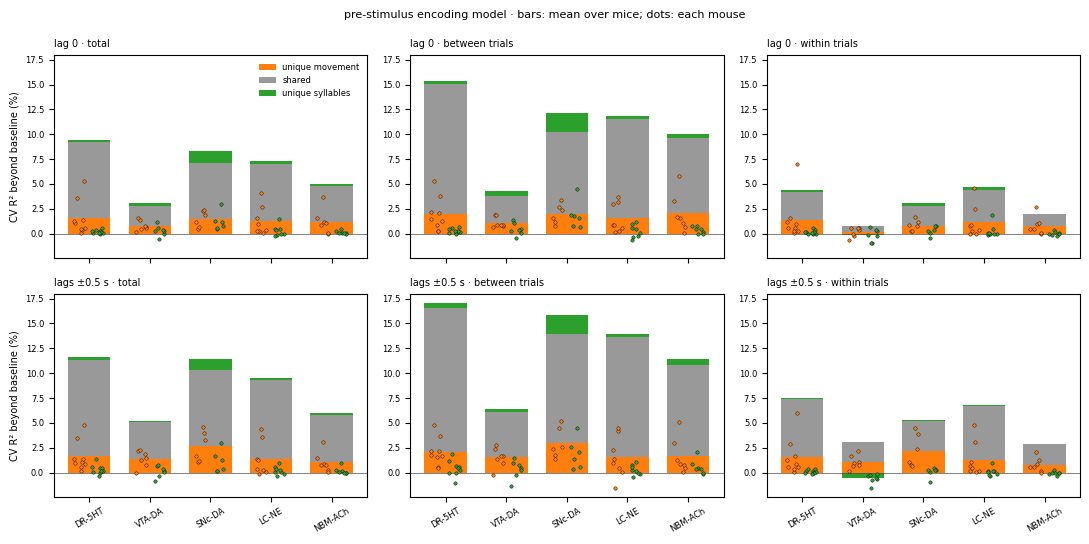

In [2]:
def per_mouse(enc):
    rows = []
    for _, r in enc.iterrows():
        R = dict(zip(MODELS, r['r2']))
        for k, part in enumerate(PARTS):
            d = {'nm': r['target_NM'], 'subject': r['subject'], 'lags': r['lags'], 'part': part,
                 **{m: R[m][k] for m in MODELS}}
            d['movement + syllables'] = R['+ both'][k] - R['baseline'][k]
            d['unique movement'] = R['+ both'][k] - R['+ syllables'][k]
            d['unique syllables'] = R['+ both'][k] - R['+ movement'][k]
            d['shared'] = d['movement + syllables'] - d['unique movement'] - d['unique syllables']
            for c in COMPONENTS:
                d[f'unique {c}'] = R['+ both'][k] - R[f'both without {c}'][k]
            rows.append(d)
    return pd.DataFrame(rows).groupby(['nm', 'subject', 'lags', 'part']).mean().mul(100).reset_index()

PM = per_mouse(ENC)
STACK = [('unique movement', 'C1'), ('shared', '0.6'), ('unique syllables', 'C2')]
fig, axes = plt.subplots(len(LAG_NAMES), len(PARTS), figsize=(11, 5.5), sharex=True)
for i, lag in enumerate(LAG_NAMES):
    for k, part in enumerate(PARTS):
        ax = axes[i, k]
        g = PM.query('lags == @lag and part == @part').groupby('nm')
        for j, nm in enumerate(NM_ORDER):
            d = g.get_group(nm); pos = neg = 0.
            for col, c in STACK:
                v = d[col].mean()
                ax.bar(j, v, bottom=pos if v >= 0 else neg, color=c, width=0.7, label=col if j == 0 else None)
                pos, neg = (pos + v, neg) if v >= 0 else (pos, neg + v)
            jit = np.random.default_rng(j).uniform(-0.1, 0.1, len(d))
            ax.scatter(j - 0.15 + jit, d['unique movement'], s=6, color='C1', ec='k', lw=0.3, zorder=3)
            ax.scatter(j + 0.15 + jit, d['unique syllables'], s=6, color='C2', ec='k', lw=0.3, zorder=3)
        ax.axhline(0, color='0.3', lw=0.5)
        ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6, rotation=30); ax.tick_params(labelsize=6)
        ax.set_title(f'{lag} · {part}', fontsize=7, loc='left')
    axes[i, 0].set_ylabel('CV R² beyond baseline (%)', fontsize=7)
common_ylim(axes)
axes[0, 0].legend(fontsize=6, frameon=False)
fig.suptitle('pre-stimulus encoding model · bars: mean over mice; dots: each mouse', fontsize=8)
plt.tight_layout(); plt.show()

Per neuromodulator: mean over mice (% CV R²), how many mice have more unique movement than unique syllables, and a Wilcoxon test of the difference across mice.

In [3]:
def compare(pm):
    out = []
    for (lag, part, nm), d in pm.groupby(['lags', 'part', 'nm']):
        diff = d['unique movement'] - d['unique syllables']
        out.append({'lags': lag, 'part': part, 'nm': nm, 'mice': len(d), 'baseline': d['baseline'].mean(),
                    'movement + syllables': d['movement + syllables'].mean(),
                    'unique movement': d['unique movement'].mean(), 'shared': d['shared'].mean(),
                    'unique syllables': d['unique syllables'].mean(),
                    'movement > syllables': f"{(diff > 0).sum()}/{len(d)}", 'p': wilcoxon(diff).pvalue})
    t = pd.DataFrame(out).set_index(['lags', 'part', 'nm'])
    return t.reindex(pd.MultiIndex.from_product([LAG_NAMES, PARTS, NM_ORDER])).round(3)

compare(PM)

mice  baseline  movement + syllables  \
lag 0       total          DR-5HT      9     2.581                 9.472   
                           VTA-DA      7     2.908                 3.102   
                           SNc-DA      6     1.613                 8.310   
                           LC-NE       8     5.835                 7.338   
                           NBM-ACh     7     6.498                 4.961   
            between trials DR-5HT      9     2.385                15.337   
                           VTA-DA      7     4.071                 4.272   
                           SNc-DA      6     1.097                12.115   
                           LC-NE       8     3.602                11.800   
                           NBM-ACh     7     3.695                10.053   
            within trials  DR-5HT      9     3.097                 4.360   
                           VTA-DA      7     0.880                 0.618   
                           SNc-DA      6     2.225                 3.103   
                           LC-NE       8     6.723                 4.697   
                           NBM-ACh     7     8.401                 1.944   
lags ±0.5 s total          DR-5HT      9     2.575                11.645   
                           VTA-DA      7     2.835                 5.181   
                           SNc-DA      6     1.711                11.393   
                           LC-NE       8     5.596                 9.502   
                           NBM-ACh     7     6.517                 5.964   
            between trials DR-5HT      9     2.391                17.022   
                           VTA-DA      7     3.989                 6.377   
                           SNc-DA      6     1.220                15.883   
                           LC-NE       8     3.445                13.957   
                           NBM-ACh     7     3.732                11.440   
            within trials  DR-5HT      9     3.086                 7.474   
                           VTA-DA      7     0.810                 2.441   
                           SNc-DA      6     2.311                 5.278   
                           LC-NE       8     6.514                 6.828   
                           NBM-ACh     7     8.414                 2.835   

                                    unique movement  shared  unique syllables  \
lag 0       total          DR-5HT             1.559   7.710             0.203   
                           VTA-DA             0.814   1.989             0.300   
                           SNc-DA             1.482   5.636             1.192   
                           LC-NE              1.300   5.724             0.313   
                           NBM-ACh            1.223   3.582             0.156   
            between trials DR-5HT             1.942  13.116             0.280   
                           VTA-DA             1.104   2.704             0.463   
                           SNc-DA             2.027   8.220             1.869   
                           LC-NE              1.569   9.964             0.267   
                           NBM-ACh            2.033   7.628             0.391   
            within trials  DR-5HT             1.383   2.825             0.152   
                           VTA-DA             0.163   0.588            -0.133   
                           SNc-DA             0.819   1.969             0.315   
                           LC-NE              1.166   3.249             0.282   
                           NBM-ACh            0.813   1.118             0.013   
lags ±0.5 s total          DR-5HT             1.615   9.722             0.308   
                           VTA-DA             1.405   3.667             0.109   
                           SNc-DA             2.621   7.664             1.108   
                           LC-NE              1.403   7.882             0.216   
                           NBM-ACh            1.035   4.719

## 2. Which component carries it?

Unique share of each movement signal and each syllable group in the full model, with lags ±0.5 s: R²(both) − R²(both without it), total R², mean ± s.e.m. across mice. The movement signals overlap with each other, as do paw state and whisking, so these shares are small next to the block totals above.

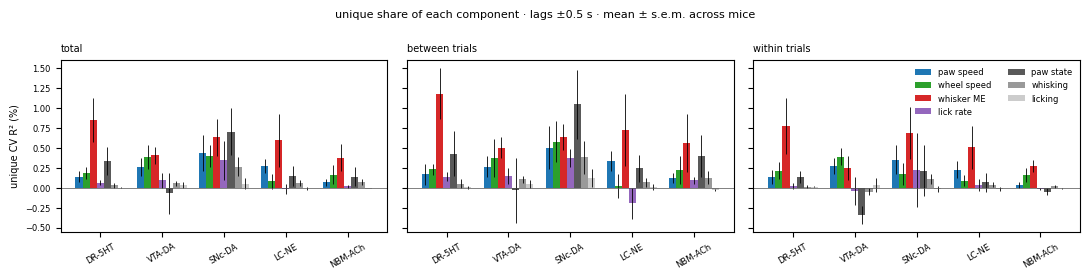

In [4]:
COLORS = dict(zip(COMPONENTS, ['C0', 'C2', 'C3', 'C4', '0.35', '0.6', '0.8']))
fig, axes = plt.subplots(1, len(PARTS), figsize=(11, 2.8), sharey=True)
for ax, part in zip(axes, PARTS):
    d = PM.query('lags == @LAG_NAMES[-1] and part == @part')
    w = 0.8 / len(COMPONENTS)
    for c_i, c in enumerate(COMPONENTS):
        for j, nm in enumerate(NM_ORDER):
            v = d.loc[d['nm'] == nm, f'unique {c}']
            ax.bar(j - 0.4 + (c_i + 0.5) * w, v.mean(), w, yerr=v.std() / np.sqrt(len(v) - 1), color=COLORS[c],
                   error_kw={'lw': 0.6}, label=c if j == 0 else None)
    ax.axhline(0, color='0.3', lw=0.5)
    ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6, rotation=30); ax.tick_params(labelsize=6)
    ax.set_title(part, fontsize=7, loc='left')
axes[0].set_ylabel('unique CV R² (%)', fontsize=7)
axes[-1].legend(fontsize=6, frameon=False, ncol=2)
fig.suptitle(f'unique share of each component · {LAG_NAMES[-1]} · mean ± s.e.m. across mice', fontsize=8)
plt.tight_layout(); plt.show()

## 3. What the lags add

R²(lags ±0.5 s) − R²(lag 0) for baseline + movement and for baseline + syllables, per mouse (dots) and mean over mice (bars). If the syllables' advantage were their temporal context, giving the continuous signals lags should close the gap.

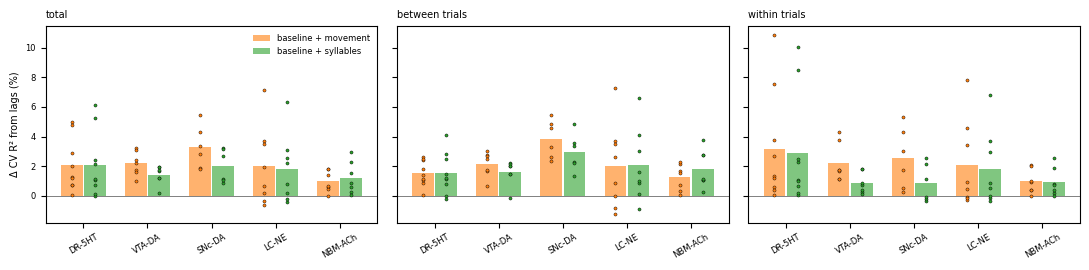

In [5]:
wide = PM.pivot_table(index=['nm', 'subject', 'part'], columns='lags', values=['+ movement', '+ syllables']).reset_index()
fig, axes = plt.subplots(1, len(PARTS), figsize=(11, 2.8), sharey=True)
for ax, part in zip(axes, PARTS):
    d = wide[wide['part'] == part]
    for o, (m, c) in enumerate([('+ movement', 'C1'), ('+ syllables', 'C2')]):
        for j, nm in enumerate(NM_ORDER):
            dd = d[d['nm'] == nm]
            gain = dd[(m, LAG_NAMES[1])] - dd[(m, LAG_NAMES[0])]
            ax.bar(j - 0.18 + 0.36 * o, gain.mean(), 0.34, color=c, alpha=0.6, label=f'baseline {m}' if j == 0 else None)
            ax.scatter(np.full(len(gain), j - 0.18 + 0.36 * o), gain, s=5, color=c, ec='k', lw=0.3, zorder=3)
    ax.axhline(0, color='0.3', lw=0.5)
    ax.set_xticks(range(len(NM_ORDER)), NM_ORDER, fontsize=6, rotation=30); ax.tick_params(labelsize=6)
    ax.set_title(part, fontsize=7, loc='left')
axes[0].set_ylabel('Δ CV R² from lags (%)', fontsize=7)
axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

## 4. Per-timestep framing

The same comparison as notebook 7, pre-stimulus only: one banded-ridge model across trials per 100 ms bin, with the predictors lagged around that bin. Mean ± s.e.m. across mice. Left pair: R² of each model. Right pair: unique movement and unique syllables. Each row shares one y scale.

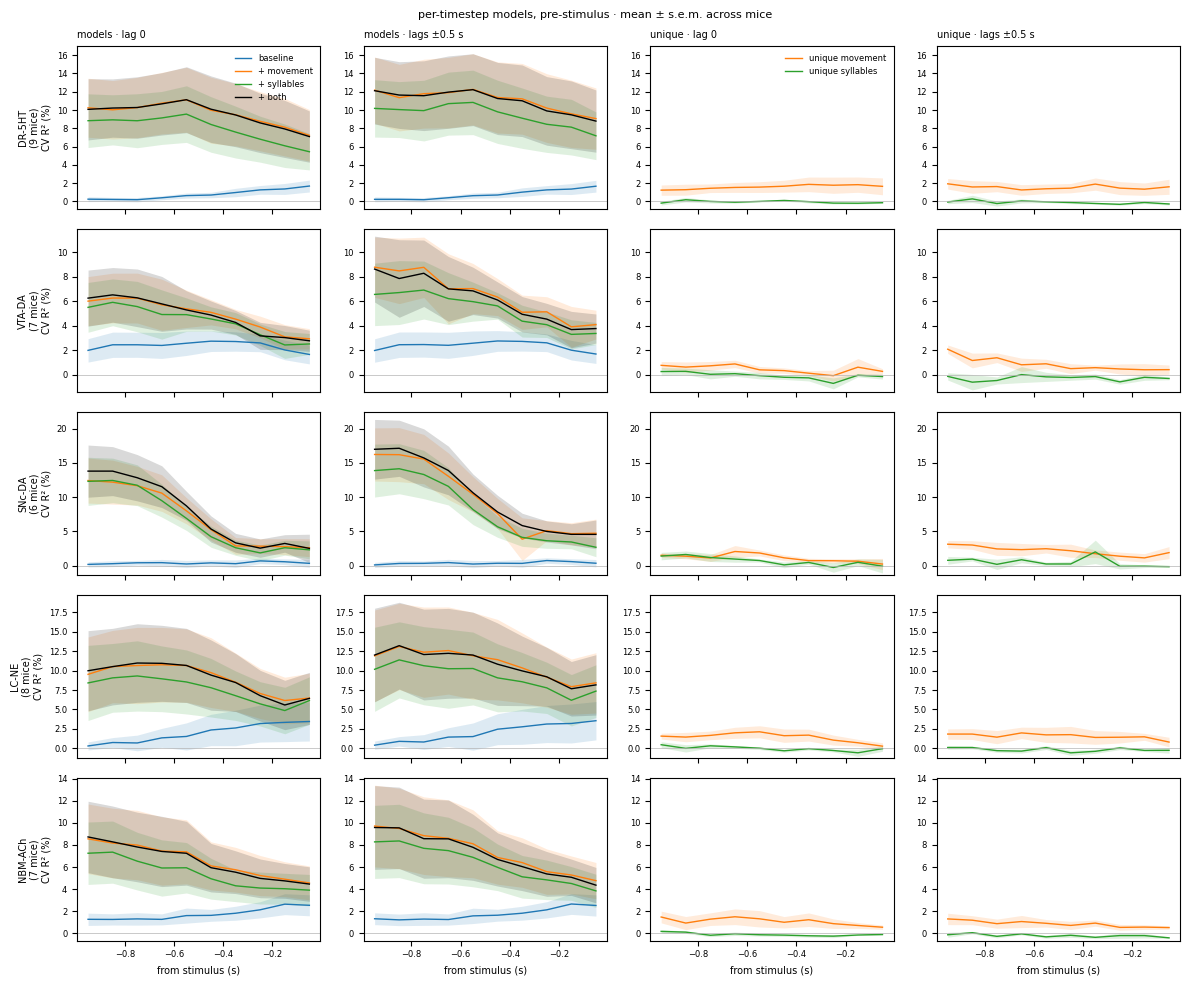

In [6]:
X = TS.attrs['bin_centres']
TS_LINES = [('baseline', 0, 'C0'), ('+ movement', 1, 'C1'), ('+ syllables', 2, 'C2'), ('+ both', 3, 'k')]
fig, axes = plt.subplots(len(NM_ORDER), 4, figsize=(12, 2 * len(NM_ORDER)), sharex=True)
for i, nm in enumerate(NM_ORDER):
    for k, lag in enumerate(LAG_NAMES):
        g = TS.query('target_NM == @nm and lags == @lag')
        mice = np.stack([np.nanmean(np.stack(gm['r2'].to_list()), 0) for _, gm in g.groupby('subject')]) * 100
        for label, m, c in TS_LINES:
            mu, se = mean_sem(mice[:, m])
            axes[i, k].plot(X, mu, color=c, lw=1, label=label); axes[i, k].fill_between(X, mu - se, mu + se, color=c, alpha=0.15, lw=0)
        for label, y, c in [('unique movement', mice[:, 3] - mice[:, 2], 'C1'), ('unique syllables', mice[:, 3] - mice[:, 1], 'C2')]:
            mu, se = mean_sem(y)
            axes[i, 2 + k].plot(X, mu, color=c, lw=1, label=label); axes[i, 2 + k].fill_between(X, mu - se, mu + se, color=c, alpha=0.15, lw=0)
    for ax in axes[i]:
        ax.axhline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
    common_ylim(axes[i])
    axes[i, 0].set_ylabel(f'{nm}\n({len(mice)} mice)\nCV R² (%)', fontsize=7)
for k, t in enumerate([f'models · {LAG_NAMES[0]}', f'models · {LAG_NAMES[1]}', f'unique · {LAG_NAMES[0]}', f'unique · {LAG_NAMES[1]}']):
    axes[0, k].set_title(t, fontsize=7, loc='left'); axes[-1, k].set_xlabel('from stimulus (s)', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False); axes[0, 2].legend(fontsize=6, frameon=False)
fig.suptitle('per-timestep models, pre-stimulus · mean ± s.e.m. across mice', fontsize=8)
plt.tight_layout(); plt.show()

## Reading (2026-11-09)

- **Movement and syllables mostly explain the same variance.** Beyond the baseline, together they explain 5–12 % of the pre-stimulus signal (total R², with lags), and most of that is shared: 3.7–9.7 % shared, 1–2.6 % unique movement, ≤ 0.3 % unique syllables except SNc.
- **With lags, continuous movement beats syllables in every neuromodulator, in nearly every mouse.** Total R²: 6/6–9/9 mice, Wilcoxon p at its floor for each n. Unique syllables is ~0 for 5-HT, VTA-DA, NE and ACh, and slightly negative within trials.
- **SNc-DA is the exception.** Syllables keep a real unique share (≈ 1.1–1.2 % total, ≈ 1.9 % between trials), and at lag 0 they tie with movement (4/6 mice, p = .44). The share comes from **paw state**, not whisking or licking. With lags, movement pulls ahead (6/6 mice) but the paw-state share remains. So before the stimulus, which paw/wheel state the mouse is in carries something about SNc dopamine beyond paw and wheel speed. That is 6 mice.
- **Whisker ME is the largest single component** for 5-HT, NE and ACh. For SNc, paw state, whisker ME and the paw/wheel speeds are all similar.
- **The effect is mostly between trials.** Trial-level differences in movement explain up to 15–17 % of the trial-mean signal, against 2–7 % within the second.
- **Lags help both sets**, by about 1–3 % R², movement a little more than syllables, mostly within trials. So the syllables' temporal context was not what gave them their share: giving the continuous signals lags widens the gap rather than closing it.
- **Per timestep**, the same picture, with explained variance falling towards stimulus onset (the quiescence period, when the mouse holds still).